# 03 — Huấn luyện, đánh giá và phân khúc

**Câu hỏi:** 10 predictor hiện tại xếp hạng churn tốt hơn baseline bao nhiêu?

Chạy bằng kernel mới sau notebook 01. Notebook 02 là phần phân tích, không cung cấp biến trong bộ nhớ.
Giữ cấu hình model hiện tại để tách việc viết lại notebook khỏi tối ưu mô hình.
Không ép AUC bằng một số mẫu; kết quả được tính lại và so với baseline.

## 1. Import thư viện

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from catboost import CatBoostClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Admin\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## 2. Đường dẫn và xác nhận dữ liệu đã xử lý

In [2]:
# Tìm project bằng đường dẫn tương đối từ thư mục làm việc.
root_candidates = [Path("."), *[Path("../" * level) for level in range(1, 7)]]
project_root = next(
    (path for path in root_candidates
     if (path / "data" / "cell2celltrain.csv").is_file()
     and (path / "work" / "pipeline").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Mở notebook từ project root hoặc work/pipeline; "
        "cần data/cell2celltrain.csv và work/pipeline/."
    )

source_path = project_root / "data" / "cell2celltrain.csv"
build_dir = project_root / "work" / "build"
processed_path = build_dir / "processed_customers.parquet"
qa_path = build_dir / "qa_report.json"
manifest_path = build_dir / "preparation_manifest.json"
display(pd.DataFrame({
    "Thành phần": ["Nguồn raw", "Processed", "Manifest"],
    "Đường dẫn tương đối": [str(source_path), str(processed_path), str(manifest_path)],
    "Tồn tại": [source_path.is_file(), processed_path.is_file(), manifest_path.is_file()],
}))

,Thành phần,Đường dẫn tương đối,Tồn tại
0,Nguồn raw,..\..\data\cell2celltrain.csv,True
1,Processed,..\..\work\build\processed_customers.parquet,True
2,Manifest,..\..\work\build\preparation_manifest.json,True


In [3]:
FEATURES = [
    "MonthsInService", "CurrentEquipmentDays", "HandsetWebCapable",
    "MonthlyRevenue", "TotalRecurringCharge", "CreditRating",
    "MonthlyMinutes", "PercChangeMinutes", "PercChangeRevenues", "PeakCallsInOut",
]
CATEGORICAL = ["HandsetWebCapable", "CreditRating"]
NUMERIC = [column for column in FEATURES if column not in CATEGORICAL]
BAND_COLUMNS = [
    "TenureBand", "EquipmentAgeBand", "ValueTier", "ChargeBand",
    "MinutesBand", "UsageTrendBand", "RevenueTrendBand",
]

In [4]:
missing_files = [
    str(path) for path in [processed_path, qa_path, manifest_path] if not path.is_file()
]
if missing_files:
    raise FileNotFoundError(
        "Chưa có dữ liệu được xác nhận. Chạy notebook 01 bằng Run All trước. "
        f"Thiếu: {missing_files}"
    )
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
qa = json.loads(qa_path.read_text(encoding="utf-8"))
if manifest.get("status") != "passed" or manifest.get("schema_version") != 1:
    raise ValueError("Manifest chưa PASS hoặc sai phiên bản; chạy lại notebook 01.")

for path, key in [
    (source_path, "source_sha256"),
    (processed_path, "processed_sha256"),
    (qa_path, "qa_sha256"),
]:
    if hashlib.sha256(path.read_bytes()).hexdigest() != manifest[key]:
        raise ValueError(f"{path.name} đã thay đổi; chạy lại notebook 01.")

data = pd.read_parquet(processed_path)
required = ["CustomerID", "Churn", *FEATURES, *BAND_COLUMNS]
if not set(required).issubset(data.columns):
    raise ValueError("Processed thiếu cột; chạy lại notebook 01.")
input_checks = pd.Series({
    "Số dòng khớp manifest/QA": len(data) == manifest["rows"] == qa["raw_rows"],
    "ID hợp lệ": data.CustomerID.notna().all() and data.CustomerID.is_unique,
    "Target nhị phân": data.Churn.isin([0, 1]).all(),
    "Churner khớp QA": int(data.Churn.sum()) == qa["target_counts"]["Yes"],
    "Numeric đúng kiểu": all(pd.api.types.is_numeric_dtype(data[c]) for c in NUMERIC),
    "Categorical không thiếu": not data[CATEGORICAL].isna().any().any(),
    "Band không thiếu": not data[BAND_COLUMNS].isna().any().any(),
}, name="PASS")
display(input_checks.to_frame())
if not input_checks.all():
    raise ValueError("Processed không hợp lệ; xem bảng kiểm tra và chạy lại notebook 01.")
print("INPUT PASS — schema, QA và SHA256 xác nhận dữ liệu đã xử lý.")

,PASS
Số dòng khớp manifest/QA,True
ID hợp lệ,True
Target nhị phân,True
Churner khớp QA,True
Numeric đúng kiểu,True
Categorical không thiếu,True
Band không thiếu,True


INPUT PASS — schema, QA và SHA256 xác nhận dữ liệu đã xử lý.


## 3. Cấu hình thí nghiệm
Tuning chỉ depth 4/6 và tối đa 450 vòng; chưa phải tìm kiếm mô hình toàn diện.

In [5]:
OUTER_SEED = 2026
DEPTH_CANDIDATES = [4, 6]
MAX_ITERATIONS = 450
LEARNING_RATE = 0.045
EARLY_STOPPING = 45
THREAD_COUNT = 4
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 10})
display(pd.Series({
    "Outer folds": 3, "Inner validation share": 0.20,
    "Depth candidates": str(DEPTH_CANDIDATES), "Max iterations": MAX_ITERATIONS,
    "Learning rate": LEARNING_RATE, "Early stopping": EARLY_STOPPING,
    "Outer seed": OUTER_SEED, "Threads": THREAD_COUNT,
}).to_frame("Cấu hình"))
display(pd.Series({
    name: importlib.metadata.version(name)
    for name in ["pandas", "numpy", "scikit-learn", "catboost"]
}).to_frame("Version"))

,Cấu hình
Outer folds,3
Inner validation share,0.2
Depth candidates,"[4, 6]"
Max iterations,450
Learning rate,0.045
Early stopping,45
Outer seed,2026
Threads,4


,Version
pandas,2.3.3
numpy,2.5.4
scikit-learn,1.9.1
catboost,1.2.10


## 4. Tách X/y
Không dùng ID, target, band hoặc retention offer trong X. Numeric NaN do CatBoost xử lý.

In [6]:
X = data[FEATURES].copy()
for column in CATEGORICAL:
    X[column] = X[column].astype(str)
y = data.Churn.astype(int).to_numpy()
if "CustomerID" in X or "Churn" in X or set(y) != {0, 1}:
    raise ValueError("X/y sai hợp đồng.")
print(f"X: {X.shape}; y: {y.shape}; churn baseline: {y.mean():.2%}")
display(X.isna().sum().to_frame("Missing numeric"))

X: (51047, 10); y: (51047,); churn baseline: 28.82%


,Missing numeric
MonthsInService,0
CurrentEquipmentDays,1
HandsetWebCapable,0
MonthlyRevenue,156
TotalRecurringCharge,156
CreditRating,0
MonthlyMinutes,156
PercChangeMinutes,367
PercChangeRevenues,367
PeakCallsInOut,0


## 5. Thiết kế OOF
Outer holdout chỉ dùng đánh giá. Inner validation trong outer train chọn depth và số vòng. Mỗi khách có đúng một dự đoán ngoài mẫu.

In [7]:
def fit_candidate(train_x, train_y, valid_x, valid_y, depth):
    candidate = CatBoostClassifier(
        iterations=MAX_ITERATIONS, depth=depth, learning_rate=LEARNING_RATE,
        loss_function="Logloss", eval_metric="Logloss", random_seed=42,
        thread_count=THREAD_COUNT, l2_leaf_reg=5, verbose=False,
        allow_writing_files=False,
    )
    candidate.fit(
        train_x, train_y, cat_features=CATEGORICAL,
        eval_set=(valid_x, valid_y), early_stopping_rounds=EARLY_STOPPING,
        use_best_model=True,
    )
    return candidate

In [8]:
splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=OUTER_SEED)
oof_scores = np.full(len(data), np.nan)
prediction_count = np.zeros(len(data), dtype=int)
fold_assignment = np.zeros(len(data), dtype=int)
fold_details = []
candidate_records = []

for fold, (train_index, holdout_index) in enumerate(splitter.split(X, y), start=1):
    print(f"Fold {fold}: train={len(train_index):,}, holdout={len(holdout_index):,}", flush=True)
    inner_train, inner_valid = train_test_split(
        train_index, test_size=0.20, stratify=y[train_index], random_state=42 + fold,
    )
    assert set(train_index).isdisjoint(holdout_index), "Outer leakage"
    assert set(inner_train).isdisjoint(inner_valid), "Inner overlap"
    candidates = {}
    for depth in DEPTH_CANDIDATES:
        candidate = fit_candidate(
            X.iloc[inner_train], y[inner_train],
            X.iloc[inner_valid], y[inner_valid], depth,
        )
        probability = candidate.predict_proba(X.iloc[inner_valid])[:, 1]
        candidates[str(depth)] = {
            "inner_validation_log_loss": float(log_loss(y[inner_valid], probability)),
            "best_iteration": int(candidate.best_iteration_),
        }
        candidate_records.append({"fold": fold, "depth": depth, **candidates[str(depth)]})
    chosen_depth = min(candidates, key=lambda key: candidates[key]["inner_validation_log_loss"])
    iterations = max(1, candidates[chosen_depth]["best_iteration"] + 1)
    model = CatBoostClassifier(
        iterations=iterations, depth=int(chosen_depth), learning_rate=LEARNING_RATE,
        loss_function="Logloss", random_seed=42 + fold, thread_count=THREAD_COUNT,
        l2_leaf_reg=5, verbose=False, allow_writing_files=False,
    )
    model.fit(X.iloc[train_index], y[train_index], cat_features=CATEGORICAL)
    probabilities = model.predict_proba(X.iloc[holdout_index])[:, 1]
    oof_scores[holdout_index] = probabilities
    prediction_count[holdout_index] += 1
    fold_assignment[holdout_index] = fold
    fold_details.append({
        "fold": fold, "train_n": len(train_index), "n": len(holdout_index),
        "selected_depth": int(chosen_depth), "iterations": iterations,
        "depth_candidates": candidates,
        "roc_auc": float(roc_auc_score(y[holdout_index], probabilities)),
        "log_loss": float(log_loss(y[holdout_index], probabilities)),
    })
    print(f"  depth={chosen_depth}, iterations={iterations}, AUC={fold_details[-1]['roc_auc']:.4f}", flush=True)

Fold 1: train=34,031, holdout=17,016


  depth=6, iterations=370, AUC=0.6695


Fold 2: train=34,031, holdout=17,016


  depth=6, iterations=353, AUC=0.6723


Fold 3: train=34,032, holdout=17,015


  depth=6, iterations=448, AUC=0.6752


In [9]:
oof_checks = pd.Series({
    "Mỗi dòng đúng một dự đoán": np.all(prediction_count == 1),
    "Score hữu hạn": np.isfinite(oof_scores).all(),
    "Score trong [0,1]": ((oof_scores >= 0) & (oof_scores <= 1)).all(),
    "Đủ 3 fold": set(fold_assignment) == {1, 2, 3},
}, name="PASS")
display(oof_checks.to_frame())
if not oof_checks.all():
    raise ValueError("OOF score không hợp lệ.")
display(pd.DataFrame(candidate_records))
display(pd.DataFrame(fold_details).drop(columns="depth_candidates"))

,PASS
Mỗi dòng đúng một dự đoán,True
Score hữu hạn,True
"Score trong [0,1]",True
Đủ 3 fold,True


,fold,depth,inner_validation_log_loss,best_iteration
0,1,4,0.565595,449
1,1,6,0.564184,369
2,2,4,0.567865,447
3,2,6,0.567332,352
4,3,4,0.563447,442
5,3,6,0.562131,447


,fold,train_n,n,selected_depth,iterations,roc_auc,log_loss
0,1,34031,17016,6,370,0.669481,0.561555
1,2,34031,17016,6,353,0.672303,0.561045
2,3,34032,17015,6,448,0.675158,0.558832


## 6. So với baseline
AP là average precision (giữ key pr_auc để tương thích dashboard). Baseline xác suất cố định bằng tỷ lệ churn là mốc mô tả.

In [10]:
metrics = {
    "model_version": "cell2cell-catboost-oof-v1",
    "source_sha256": manifest["source_sha256"],
    "processed_sha256": manifest["processed_sha256"],
    "chosen_depth": int(pd.Series([f["selected_depth"] for f in fold_details]).mode().iloc[0]),
    "depth_selection": "inside each outer training fold", "folds": fold_details,
    "roc_auc": float(roc_auc_score(y, oof_scores)),
    "pr_auc": float(average_precision_score(y, oof_scores)),
    "log_loss": float(log_loss(y, oof_scores)),
    "brier": float(brier_score_loss(y, oof_scores)),
    "baseline_churn_rate": float(y.mean()), "score_type": "3-fold out-of-fold",
}
baseline_probability = np.full(len(y), y.mean())
comparison = pd.DataFrame({
    "Baseline": [0.5, y.mean(), log_loss(y, baseline_probability), brier_score_loss(y, baseline_probability)],
    "CatBoost OOF": [metrics["roc_auc"], metrics["pr_auc"], metrics["log_loss"], metrics["brier"]],
}, index=["ROC-AUC ↑", "Average precision ↑", "Log loss ↓", "Brier ↓"])
display(comparison)
display(Markdown(
    f"**Nhận xét:** ROC-AUC **{metrics['roc_auc']:.4f}**, AP **{metrics['pr_auc']:.4f}**. "
    f"Log loss giảm **{1 - metrics['log_loss'] / comparison.loc['Log loss ↓', 'Baseline']:.1%}** so với baseline. "
    "Chưa chứng minh hiệu quả chính sách."
))

,Baseline,CatBoost OOF
ROC-AUC ↑,0.500000,0.672287
Average precision ↑,0.288185,0.453602
Log loss ↓,0.600519,0.560477
Brier ↓,0.205135,0.188908


**Nhận xét:** ROC-AUC **0.6723**, AP **0.4536**. Log loss giảm **6.7%** so với baseline. Chưa chứng minh hiệu quả chính sách.

### ROC và precision–recall
ROC có đường ngẫu nhiên; PR có baseline bằng tỷ lệ churn.

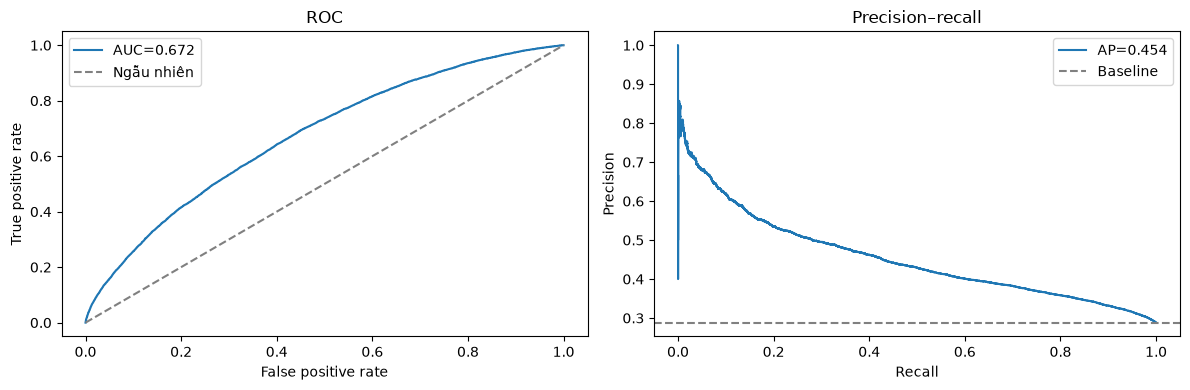

In [11]:
fpr, tpr, _ = roc_curve(y, oof_scores)
precision, recall, _ = precision_recall_curve(y, oof_scores)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fpr, tpr, label=f"AUC={metrics['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Ngẫu nhiên")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
axes[1].plot(recall, precision, label=f"AP={metrics['pr_auc']:.3f}")
axes[1].axhline(y.mean(), linestyle="--", color="gray", label="Baseline")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Decile và calibration
Decile 10 risk cao nhất. Calibration so xác suất dự đoán với churn quan sát.

,Customers,Churners,MeanRisk,ChurnRate
RiskDecile,,,,
1,5104,507,0.108944,0.099334
2,5105,798,0.157922,0.156317
3,5105,981,0.199187,0.192165
4,5104,1199,0.237378,0.234914
5,5105,1343,0.268085,0.263075
6,5105,1529,0.294214,0.299510
7,5104,1623,0.322486,0.317986
8,5105,1799,0.357250,0.352400
9,5105,2154,0.406312,0.421939


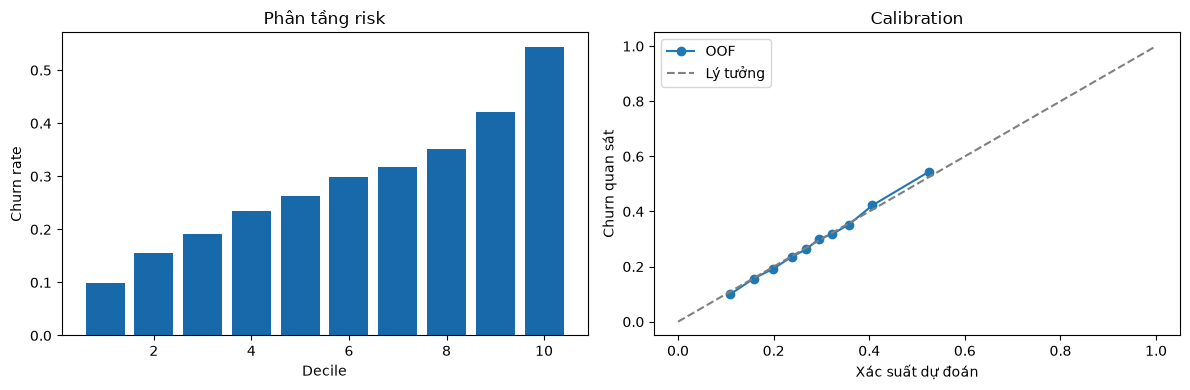

**Quan sát:** decile 1 churn 9.93%; decile 10 churn 54.42%. Cần holdout theo thời gian trước vận hành.

In [12]:
mart = data.copy()
mart["RiskScore"] = oof_scores
rank = pd.Series(oof_scores).rank(method="first", pct=True).to_numpy()
mart["RiskDecile"] = np.ceil(rank * 10).astype(int).clip(1, 10)
deciles = mart.groupby("RiskDecile").agg(
    Customers=("Churn", "size"), Churners=("Churn", "sum"),
    MeanRisk=("RiskScore", "mean"), ChurnRate=("Churn", "mean"),
)
display(deciles)
observed, predicted = calibration_curve(y, oof_scores, n_bins=10, strategy="quantile")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(deciles.index, deciles.ChurnRate, color="#1769aa")
axes[0].set(xlabel="Decile", ylabel="Churn rate", title="Phân tầng risk")
axes[1].plot(predicted, observed, "o-", label="OOF")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Lý tưởng")
axes[1].set(xlabel="Xác suất dự đoán", ylabel="Churn quan sát", title="Calibration")
axes[1].legend()
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Quan sát:** decile 1 churn {deciles.loc[1, 'ChurnRate']:.2%}; "
    f"decile 10 churn {deciles.loc[10, 'ChurnRate']:.2%}. "
    "Cần holdout theo thời gian trước vận hành."
))

## 8. Capacity và cumulative gain
Precision = churner/top khách; recall = churner trong top/tổng churner; lift = precision/baseline.

,Capacity,n,churners,precision,recall,lift
0,5%,2553,1554,0.608696,0.105635,2.112167
1,10%,5105,2778,0.544172,0.188838,1.888272
2,20%,10210,4932,0.483056,0.335259,1.676198


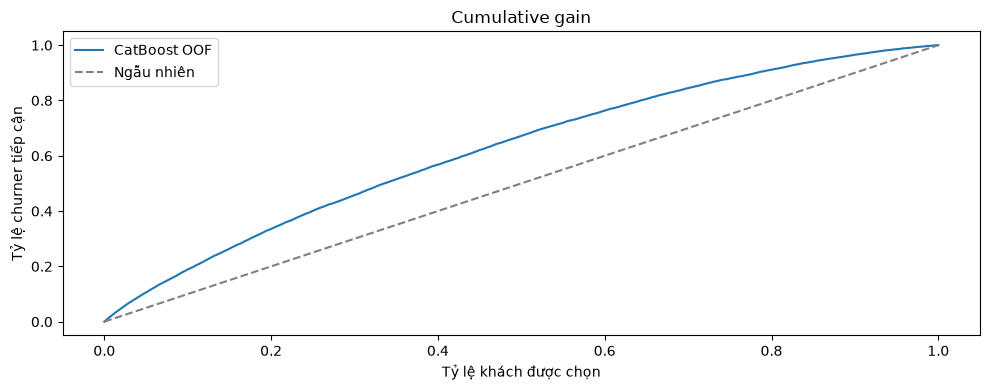

**Top 10%:** 5,105 khách, precision 54.42%, recall 18.88%, lift 1.89×. Đây là churner quá khứ được tiếp cận, không phải số được cứu giữ.

In [13]:
capacity_records = []
for share in [0.05, 0.10, 0.20]:
    top = mart.nlargest(int(np.ceil(len(mart) * share)), "RiskScore")
    result = {
        "n": len(top), "churners": int(top.Churn.sum()),
        "precision": float(top.Churn.mean()),
        "recall": float(top.Churn.sum() / mart.Churn.sum()),
        "lift": float(top.Churn.mean() / mart.Churn.mean()),
    }
    metrics[f"capacity_{int(share * 100)}"] = result
    capacity_records.append({"Capacity": f"{share:.0%}", **result})
display(pd.DataFrame(capacity_records))
ordered = mart.sort_values("RiskScore", ascending=False)
population = np.arange(1, len(ordered) + 1) / len(ordered)
gain = ordered.Churn.cumsum().to_numpy() / mart.Churn.sum()
fig, ax = plt.subplots()
ax.plot(population, gain, label="CatBoost OOF")
ax.plot([0, 1], [0, 1], "--", label="Ngẫu nhiên", color="gray")
ax.set(xlabel="Tỷ lệ khách được chọn", ylabel="Tỷ lệ churner tiếp cận", title="Cumulative gain")
ax.legend()
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Top 10%:** {metrics['capacity_10']['n']:,} khách, "
    f"precision {metrics['capacity_10']['precision']:.2%}, "
    f"recall {metrics['capacity_10']['recall']:.2%}, lift {metrics['capacity_10']['lift']:.2f}×. "
    "Đây là churner quá khứ được tiếp cận, không phải số được cứu giữ."
))

## 9. P1–P4 và ReasonCode
Rule có thứ tự ưu tiên. ReasonCode là tín hiệu rà soát, không phải SHAP hay nguyên nhân.

In [14]:
mart["ValuePriority"] = np.select(
    [mart.MonthlyRevenue.ge(70), mart.MonthlyRevenue.ge(35)],
    ["Cao", "Trung bình"], default="Thấp/không rõ",
)
mart["PrioritySegment"] = np.select(
    [mart.RiskDecile.ge(9) & mart.MonthlyRevenue.ge(70),
     mart.RiskDecile.ge(9),
     mart.RiskDecile.ge(7) & mart.MonthlyRevenue.ge(70)],
    ["P1 · Risk cao / value cao", "P2 · Risk cao", "P3 · Value cao / risk khá"],
    default="P4 · Theo dõi",
)
mart["ReasonCode"] = np.select(
    [mart.CurrentEquipmentDays.ge(730) | mart.HandsetWebCapable.eq("No"),
     mart.PercChangeMinutes.le(-83), mart.MonthsInService.between(12, 18),
     mart.TotalRecurringCharge.gt(60) & mart.MonthlyMinutes.lt(150)],
    ["Thiết bị cần rà soát", "Sử dụng suy giảm", "Giai đoạn vòng đời", "Gói cước cần rà soát"],
    default="Rà soát chung",
)
segments = mart.groupby("PrioritySegment").agg(
    Customers=("Churn", "size"), Churners=("Churn", "sum"), ChurnRate=("Churn", "mean"),
)
display(segments)
if segments.Customers.sum() != len(mart):
    raise ValueError("Segment không phủ toàn bộ khách.")

,Customers,Churners,ChurnRate
PrioritySegment,,,
P1 · Risk cao / value cao,2443,1121,0.458862
P2 · Risk cao,7767,3811,0.490666
P3 · Value cao / risk khá,2033,689,0.338908
P4 · Theo dõi,38804,9090,0.234254


### Ma trận policy
Eligibility thiết bị dùng ≥730 thống nhất với rule. Các treatment là giả thuyết cần control và guardrail.

In [15]:
policy = pd.DataFrame([
    ["Thiết bị cần rà soát", "Risk decile ≥7; thiết bị ≥730 ngày hoặc không web-capable",
     "Device review / hướng dẫn / upgrade pilot", "Incremental retention",
     "Chi phí trợ giá, khiếu nại", "Ưu tiên pilot"],
    ["Sử dụng suy giảm", "Risk decile ≥7; mức thay đổi minutes nguồn ≤-83",
     "Re-engagement / plan review", "Incremental retention, usage recovery",
     "Opt-out, contact fatigue", "Ưu tiên pilot"],
    ["Giai đoạn vòng đời", "Risk decile ≥7; tenure 12–18 tháng",
     "Check-in và giải thích gói", "Incremental retention",
     "Contact fatigue, offer cost", "Ưu tiên pilot"],
    ["Gói cước cần rà soát", "Risk decile ≥7; charge >60 và minutes <150",
     "Bill review / right-size plan", "Incremental retention, plan acceptance",
     "Revenue dilution", "Khám phá thêm"],
    ["Rà soát chung", "Risk decile ≥7; không khớp rule cụ thể",
     "Customer care review", "Incremental retention", "Cost per save", "Fallback, chưa pilot"],
], columns=[
    "ReasonCode", "Eligibility hypothesis", "Treatment hypothesis",
    "Primary KPI", "Guardrail", "Status",
])
eligible = mart[mart.RiskDecile.ge(7)].groupby("ReasonCode").agg(
    Eligible=("Churn", "size"), ChurnRate=("Churn", "mean"),
)
display(policy.merge(eligible, on="ReasonCode", how="left"))
if not policy.ReasonCode.is_unique or set(policy.ReasonCode) != set(mart.ReasonCode):
    raise ValueError("Policy không phủ đúng reason.")

,ReasonCode,Eligibility hypothesis,Treatment hypothesis,Primary KPI,Guardrail,Status,Eligible,ChurnRate
0,Thiết bị cần rà soát,Risk decile ≥7; thiết bị ≥730 ngày hoặc không ...,Device review / hướng dẫn / upgrade pilot,Incremental retention,"Chi phí trợ giá, khiếu nại",Ưu tiên pilot,5659,0.401308
1,Sử dụng suy giảm,Risk decile ≥7; mức thay đổi minutes nguồn ≤-83,Re-engagement / plan review,"Incremental retention, usage recovery","Opt-out, contact fatigue",Ưu tiên pilot,5455,0.429881
2,Giai đoạn vòng đời,Risk decile ≥7; tenure 12–18 tháng,Check-in và giải thích gói,Incremental retention,"Contact fatigue, offer cost",Ưu tiên pilot,4504,0.388544
3,Gói cước cần rà soát,Risk decile ≥7; charge >60 và minutes <150,Bill review / right-size plan,"Incremental retention, plan acceptance",Revenue dilution,Khám phá thêm,96,0.541667
4,Rà soát chung,Risk decile ≥7; không khớp rule cụ thể,Customer care review,Incremental retention,Cost per save,"Fallback, chưa pilot",4705,0.411477


## 10. Xuất và đọc lại đối soát
Metric từ dữ liệu thực; không hard-code AUC hoặc kiểm tra phải tốt hơn baseline mới cho chạy.

In [16]:
mart_path = build_dir / "customer_mart.parquet"
metrics_path = build_dir / "model_metrics.json"
policy_path = build_dir / "policy_matrix.csv"
metrics["package_versions"] = {
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "scikit-learn", "catboost"]
}
mart.to_parquet(mart_path, index=False)
metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
policy.to_csv(policy_path, index=False, encoding="utf-8-sig")
reloaded = pd.read_parquet(mart_path)
pd.testing.assert_frame_equal(mart, reloaded)
stored_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
stored_policy = pd.read_csv(policy_path)
checks = pd.Series({
    "Dòng/target khớp QA": len(reloaded) == qa["raw_rows"] and int(reloaded.Churn.sum()) == qa["target_counts"]["Yes"],
    "Score đầy đủ": reloaded.RiskScore.notna().all(),
    "AUC khớp mart": np.isclose(roc_auc_score(reloaded.Churn, reloaded.RiskScore), stored_metrics["roc_auc"]),
    "AP khớp mart": np.isclose(average_precision_score(reloaded.Churn, reloaded.RiskScore), stored_metrics["pr_auc"]),
    "Policy phủ reason": set(stored_policy.ReasonCode) == set(reloaded.ReasonCode),
}, name="PASS")
display(checks.to_frame())
if not checks.all():
    raise ValueError("Artifact không đối soát.")
print("03 PASS — mart, metrics và policy đã đọc lại thành công.")

,PASS
Dòng/target khớp QA,True
Score đầy đủ,True
AUC khớp mart,True
AP khớp mart,True
Policy phủ reason,True


03 PASS — mart, metrics và policy đã đọc lại thành công.


### Kết luận và giới hạn

Đọc kết quả cùng baseline, decile và capacity. Phạm vi 10 feature/depth 4–6/450 vòng còn hạn chế;
chưa có benchmark nhiều model, holdout theo thời gian hoặc kiểm tra drift.
Chưa xác nhận timing predictor, đơn vị PercChange, fairness của CreditRating hoặc cost/uplift để báo ROI.